In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor

In [16]:
# Параметры варианта
a = 0.1
b = 0.3
c = 0.08
d = 0.3

# Количество входных нейронов
n_inputs = 10

# Количество нейронов скрытого слоя
n_hidden = 4

In [17]:
# Генерация значений аргумента
x = np.linspace(0, 40, 400)

# Вычисление значений функции
y = a * np.cos(b * x) + c * np.sin(d * x)

# Формирование входных и выходных данных
X = np.array([y[i:i+n_inputs] for i in range(len(y)-n_inputs)])
Y = y[n_inputs:]

print("Количество входных данных:", len(X))
print("Количество выходных данных:", len(Y))

Количество входных данных: 390
Количество выходных данных: 390


In [18]:
# Разделение данных: 80% для обучения, 20% для тестирования
split = int(len(X) * 0.8)

X_train = X[:split]
Y_train = Y[:split]

X_test = X[split:]
Y_test = Y[split:]

print("Обучающая выборка:", len(X_train))
print("Тестовая выборка:", len(X_test))

Обучающая выборка: 312
Тестовая выборка: 78


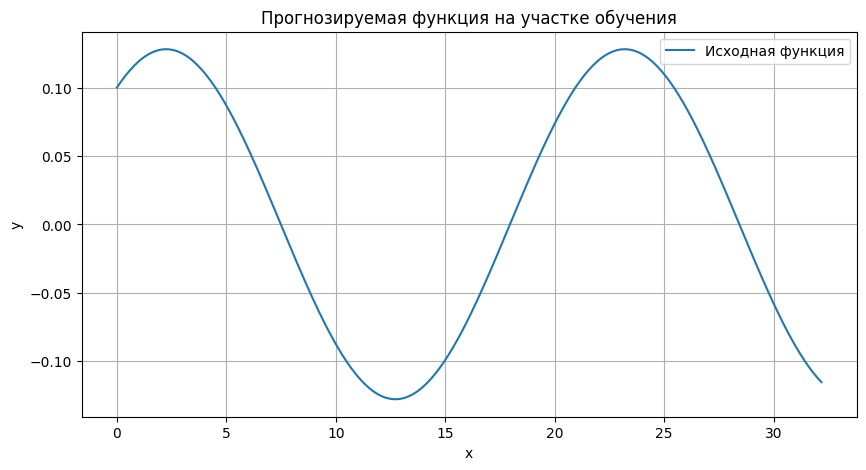

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(x[:split+n_inputs], y[:split+n_inputs], label='Исходная функция')

plt.title('Прогнозируемая функция на участке обучения')
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.legend()

plt.show()

In [20]:
# Создание нейронной сети
model = MLPRegressor(
    hidden_layer_sizes=(n_hidden,),
    activation='logistic',
    solver='adam',
    max_iter=3000,
    random_state=42,
    tol=1e-8
)

# Обучение сети
model.fit(X_train, Y_train)

print("Обучение завершено")

Обучение завершено


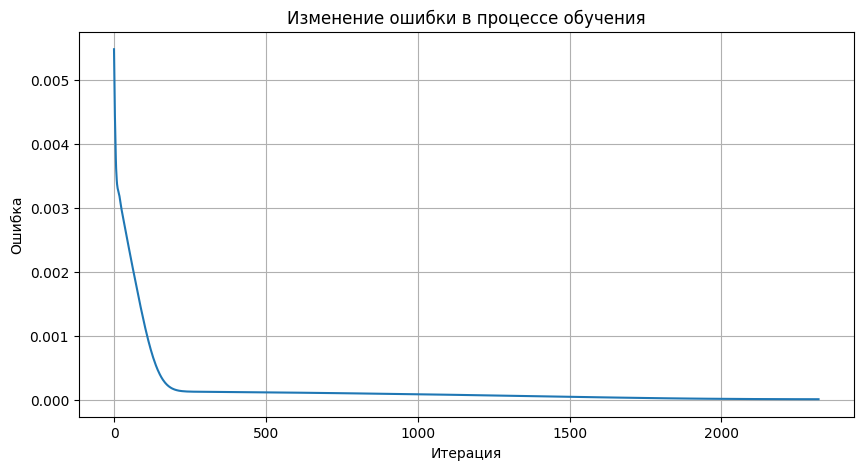

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(model.loss_curve_)

plt.title('Изменение ошибки в процессе обучения')
plt.xlabel('Итерация')
plt.ylabel('Ошибка')
plt.grid()

plt.show()

In [22]:
# Получение результатов на обучающей выборке
Y_train_pred = model.predict(X_train)

# Формирование таблицы
train_results = pd.DataFrame({
    'Эталонное значение': Y_train,
    'Полученное значение': Y_train_pred,
    'Отклонение': np.abs(Y_train - Y_train_pred)
})

train_results

,Эталонное значение,Полученное значение,Отклонение
0,0.119210,0.117446,0.001765
1,0.120563,0.118803,0.001760
2,0.121807,0.120055,0.001753
3,0.122941,0.121200,0.001741
4,0.123964,0.122237,0.001727
...,...,...,...
307,-0.108113,-0.107655,0.000458
308,-0.110128,-0.109725,0.000403
309,-0.112044,-0.111695,0.000349
310,-0.113858,-0.113564,0.000295


In [23]:
# Получение результатов на тестовой выборке
Y_test_pred = model.predict(X_test)

# Формирование таблицы
test_results = pd.DataFrame({
    'Эталонное значение': Y_test,
    'Полученное значение': Y_test_pred,
    'Отклонение': np.abs(Y_test - Y_test_pred)
})

test_results

,Эталонное значение,Полученное значение,Отклонение
0,-0.117176,-0.116990,0.000186
1,-0.118677,-0.118545,0.000131
2,-0.120070,-0.119993,0.000077
3,-0.121355,-0.121333,0.000022
4,-0.122530,-0.122563,0.000033
...,...,...,...
73,0.026619,0.025012,0.001607
74,0.030374,0.028782,0.001591
75,0.034101,0.032523,0.001578
76,0.037797,0.036231,0.001566
